# 02 - Perceptrons, Activation Functions, Forward & Backward Propagation
**Learning goals:** perceptron model, activation functions and their derivatives, forward pass, backward pass (chain rule) worked by hand and verified in code.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
np.random.seed(0)

## 1. The Perceptron
A single neuron: $z = w \cdot x + b$, output $\hat y = f(z)$.
The classic perceptron uses a **step** function. Learning rule: $w \leftarrow w + \eta (y - \hat y)\,x$.

In [2]:
class Perceptron:
    def __init__(self, lr=0.1, epochs=20):
        self.lr, self.epochs = lr, epochs
    def fit(self, X, y):
        self.w, self.b, self.errors = np.zeros(X.shape[1]), 0.0, []
        for _ in range(self.epochs):
            err = 0
            for xi, yi in zip(X, y):
                update = self.lr * (yi - self.predict(xi))
                self.w += update * xi; self.b += update
                err += int(update != 0)
            self.errors.append(err)
        return self
    def predict(self, X): return np.where(np.dot(X, self.w) + self.b >= 0, 1, 0)

# AND and OR are linearly separable; XOR is not
X = np.array([[0,0],[0,1],[1,0],[1,1]])
for name, y in {'AND':[0,0,0,1], 'OR':[0,1,1,1], 'XOR':[0,1,1,0]}.items():
    p = Perceptron().fit(X, np.array(y))
    print(f'{name}: predictions={p.predict(X)}  target={y}  final-epoch-errors={p.errors[-1]}')

AND: predictions=[0 0 0 1]  target=[0, 0, 0, 1]  final-epoch-errors=0
OR: predictions=[0 1 1 1]  target=[0, 1, 1, 1]  final-epoch-errors=0
XOR: predictions=[1 1 0 0]  target=[0, 1, 1, 0]  final-epoch-errors=4


**Key insight:** XOR fails - a single perceptron can only draw a straight line. We need hidden layers + non-linear activations.

## 2. Activation functions and derivatives

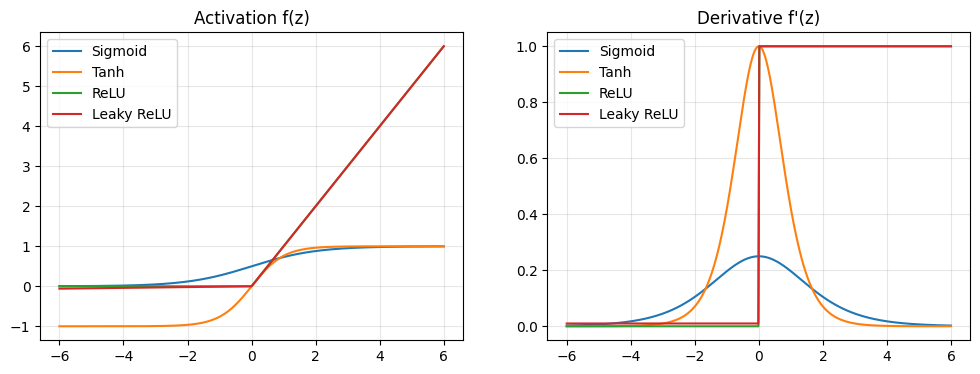

In [3]:
def sigmoid(z): return 1/(1+np.exp(-z))
acts = {
 'Sigmoid':    (sigmoid,                        lambda z: sigmoid(z)*(1-sigmoid(z))),
 'Tanh':       (np.tanh,                        lambda z: 1-np.tanh(z)**2),
 'ReLU':       (lambda z: np.maximum(0,z),      lambda z: (z>0).astype(float)),
 'Leaky ReLU': (lambda z: np.where(z>0,z,0.01*z), lambda z: np.where(z>0,1,0.01)),
}
z = np.linspace(-6, 6, 400)
fig, ax = plt.subplots(1, 2, figsize=(12,4))
for n,(f,d) in acts.items():
    ax[0].plot(z, f(z), label=n); ax[1].plot(z, d(z), label=n)
ax[0].set_title('Activation f(z)'); ax[1].set_title("Derivative f'(z)")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.show()

| Function | Range | Use | Issue |
|---|---|---|---|
| Sigmoid | (0,1) | binary output layer | vanishing gradient |
| Tanh | (-1,1) | hidden layers (zero-centred) | vanishing gradient |
| ReLU | [0,inf) | default for hidden layers | "dying ReLU" |
| Leaky ReLU | (-inf,inf) | fixes dying ReLU | extra hyper-parameter |
| Softmax | (0,1), sums to 1 | multi-class output | - |

## 3. Forward propagation (2-2-1 network)
$Z^{[1]} = XW^{[1]}+b^{[1]},\; A^{[1]}=\sigma(Z^{[1]}),\; Z^{[2]}=A^{[1]}W^{[2]}+b^{[2]},\; \hat y=\sigma(Z^{[2]})$

In [4]:
X = np.array([[0.5, -1.0]])      # one sample
y = np.array([[1.0]])
W1 = np.array([[0.1, 0.4],[-0.3, 0.2]]); b1 = np.zeros((1,2))
W2 = np.array([[0.7],[-0.5]]);           b2 = np.zeros((1,1))

Z1 = X @ W1 + b1;  A1 = sigmoid(Z1)
Z2 = A1 @ W2 + b2; y_hat = sigmoid(Z2)
loss = -(y*np.log(y_hat) + (1-y)*np.log(1-y_hat))
print('Z1', Z1, '\nA1', A1, '\nZ2', Z2, '\ny_hat', y_hat, '\nloss', loss)

Z1 [[0.35 0.  ]] 
A1 [[0.58661758 0.5       ]] 
Z2 [[0.16063231]] 
y_hat [[0.54007195]] 
loss [[0.61605291]]


## 4. Backward propagation (chain rule)
With sigmoid output + binary cross-entropy, the output error simplifies to **$dZ^{[2]} = \hat y - y$**. Then:

$dW^{[2]} = A^{[1]T}dZ^{[2]}$, $db^{[2]} = dZ^{[2]}$, $dA^{[1]} = dZ^{[2]}W^{[2]T}$, $dZ^{[1]} = dA^{[1]} \odot \sigma'(Z^{[1]})$, $dW^{[1]}=X^T dZ^{[1]}$

In [5]:
dZ2 = y_hat - y
dW2 = A1.T @ dZ2;  db2 = dZ2
dA1 = dZ2 @ W2.T
dZ1 = dA1 * A1*(1-A1)
dW1 = X.T @ dZ1;   db1 = dZ1
print('dW1\n', dW1, '\ndW2\n', dW2)

dW1
 [[-0.03903597  0.0287455 ]
 [ 0.07807195 -0.05749101]] 
dW2
 [[-0.26980188]
 [-0.22996403]]


## 5. Verify with numerical gradient checking

In [6]:
def loss_fn(W1_, W2_):
    a1 = sigmoid(X @ W1_ + b1); yh = sigmoid(a1 @ W2_ + b2)
    return (-(y*np.log(yh) + (1-y)*np.log(1-yh))).item()

eps, num = 1e-6, np.zeros_like(W1)
for i in range(W1.shape[0]):
    for j in range(W1.shape[1]):
        P, M = W1.copy(), W1.copy(); P[i,j]+=eps; M[i,j]-=eps
        num[i,j] = (loss_fn(P,W2)-loss_fn(M,W2))/(2*eps)
print('Analytic:\n', dW1, '\nNumerical:\n', num)
print('Max difference:', np.abs(dW1-num).max())

Analytic:
 [[-0.03903597  0.0287455 ]
 [ 0.07807195 -0.05749101]] 
Numerical:
 [[-0.03903597  0.0287455 ]
 [ 0.07807195 -0.05749101]]
Max difference: 6.670981128609199e-11


## 6. Solving XOR with a hidden layer (preview of notebook 04)

XOR predictions: [0.    0.999 0.999 0.002] -> classes [0 1 1 0]


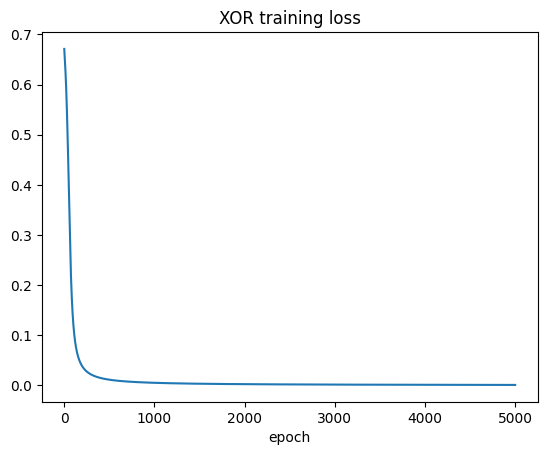

In [7]:
X = np.array([[0,0],[0,1],[1,0],[1,1]], float); y = np.array([[0],[1],[1],[0]], float)
rng = np.random.default_rng(1)
W1 = rng.normal(0,1,(2,4)); b1 = np.zeros((1,4)); W2 = rng.normal(0,1,(4,1)); b2 = np.zeros((1,1))
losses = []
for ep in range(5000):
    A1 = np.tanh(X@W1+b1); yh = sigmoid(A1@W2+b2)
    losses.append(-np.mean(y*np.log(yh)+(1-y)*np.log(1-yh)))
    dZ2 = (yh-y)/4; dW2 = A1.T@dZ2; db2 = dZ2.sum(0, keepdims=True)
    dZ1 = (dZ2@W2.T)*(1-A1**2); dW1 = X.T@dZ1; db1 = dZ1.sum(0, keepdims=True)
    W1-=0.5*dW1; b1-=0.5*db1; W2-=0.5*dW2; b2-=0.5*db2
print('XOR predictions:', yh.round(3).ravel(), '-> classes', (yh>0.5).astype(int).ravel())
plt.plot(losses); plt.title('XOR training loss'); plt.xlabel('epoch'); plt.show()

## 7. Practice tasks
1. Train the perceptron on the NAND gate.
2. Replace tanh with ReLU in the XOR network. Does it still converge?
3. Derive and implement `dZ` for a **softmax + cross-entropy** output (3 classes).